# House Price Prediction — Data Cleaning, Modeling & Export

**Dataset:** House Price by Juhi Bhojani — https://www.kaggle.com/datasets/juhibhojani/house-price

> This notebook ships with a small **synthetic** `house_prices.csv` (see `data/generate_synthetic_data.py`)
> that mirrors the real Kaggle dataset's columns and messiness, so the whole pipeline runs out of the box.
> **Replace `data/house_prices.csv` with the real Kaggle file** before submitting the assignment — no code
> changes should be needed since the column names and formats match.


## 2.1 Load & Inspect

In [1]:
import pandas as pd

df = pd.read_csv("data/house_prices.csv")
df.shape

(8000, 21)

In [2]:
df.head()

,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,...,facing,overlooking,Society,Bathroom,Balcony,Car Parking,Ownership,Super Area,Dimensions,Plot Area
0,0,"2 BHK Flat in Sector 58, Pune","Well maintained property, close to schools and...",1.07 Cr,10688000.0,"Sector 58, Pune",1523 sqft,Ready to Move,Basement out of 12,Resale,...,NaN,Pool,Society 262,3.0,1.0,3.0,Power of Attorney,NaN,NaN,NaN
1,1,"2 BHK Flat in Sector 51, Bangalore","Well maintained property, close to schools and...",85.6 Lac,8558000.0,"Sector 51, Bangalore",NaN,Ready to Move,15 out of 17,Resale,...,North-East,Pool,Society 191,4.0,1.0,NaN,Co-operative Society,NaN,NaN,NaN
2,2,"3 BHK Flat in Sector 31, Noida",NaN,37.8 Lac,3782000.0,"Sector 31, Noida",515 sqft,Under Construction,5 out of 15,Resale,...,North,NaN,Society 398,2.0,2.0,NaN,Leasehold,714 sqft,NaN,NaN
3,3,"3 BHK Flat in Sector 55, Navi Mumbai","Well maintained property, close to schools and...",72.7 Lac,7266000.0,"Sector 55, Navi Mumbai",NaN,Ready to Move,4 out of 15,Resale,...,North,Pool,Society 109,NaN,1.0,3.0,Co-operative Society,NaN,NaN,NaN
4,4,"2 BHK Flat in Sector 37, Noida",NaN,1.47 Cr,14661000.0,"Sector 37, Noida",1320 sqft,Ready to Move,4 out of 24,New Property,...,South,Main Road,Society 269,1.0,1.0,0.0,Co-operative Society,1672 sqft,NaN,NaN


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 21 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Index              8000 non-null   int64  
 1   Title              8000 non-null   str    
 2   Description        5532 non-null   str    
 3   Amount(in rupees)  7928 non-null   str    
 4   Price (in rupees)  8000 non-null   float64
 5   location           7855 non-null   str    
 6   Carpet Area        6804 non-null   str    
 7   Status             8000 non-null   str    
 8   Floor              7250 non-null   str    
 9   Transaction        8000 non-null   str    
 10  Furnishing         7247 non-null   str    
 11  facing             6875 non-null   str    
 12  overlooking        6045 non-null   str    
 13  Society            7974 non-null   str    
 14  Bathroom           7607 non-null   float64
 15  Balcony            6369 non-null   float64
 16  Car Parking        5602 non-null   

In [4]:
df.describe()

,Index,Price (in rupees),Bathroom,Balcony,Car Parking,Dimensions,Plot Area
count,8000.00000,8.000000e+03,7607.000000,6369.000000,5602.000000,0.0,0.0
mean,3999.50000,1.100579e+07,2.135533,1.181975,0.963763,NaN,NaN
std,2309.54541,1.160762e+07,1.248995,1.072885,0.927437,NaN,NaN
min,0.00000,5.800000e+04,1.000000,0.000000,0.000000,NaN,NaN
25%,1999.75000,5.742000e+06,1.000000,0.000000,0.000000,NaN,NaN
50%,3999.50000,9.150500e+06,2.000000,1.000000,1.000000,NaN,NaN
75%,5999.25000,1.351825e+07,3.000000,2.000000,2.000000,NaN,NaN
max,7999.00000,2.696340e+08,6.000000,4.000000,3.000000,NaN,NaN


In [5]:
df.isna().mean().sort_values(ascending=False)  # % missing per column

Plot Area            1.000000
Dimensions           1.000000
Super Area           0.403500
Description          0.308500
Car Parking          0.299750
overlooking          0.244375
Balcony              0.203875
Ownership            0.196250
Carpet Area          0.149500
facing               0.140625
Furnishing           0.094125
Floor                0.093750
Bathroom             0.049125
location             0.018125
Amount(in rupees)    0.009000
Society              0.003250
Index                0.000000
Price (in rupees)    0.000000
Title                0.000000
Transaction          0.000000
Status               0.000000
dtype: float64

**Answers:**
- **Rows/columns:** the dataset has several thousand listings and 21 raw columns (see `df.shape` above).
- **Numeric vs text:** `Price (in rupees)`, `Bathroom`, `Balcony`, `Car Parking` load as numeric; `Amount(in rupees)`,
  `Carpet Area`, `Super Area`, `Floor`, `location`, `Society`, `Furnishing`, `Transaction`, `Ownership`, `facing`,
  `overlooking`, `Status`, `Title`, `Description` are text/object columns that need parsing.
- **Most missing:** `Dimensions` and `Plot Area` are almost entirely empty and are dropped; `Society`, `Super Area`,
  `Description`, `overlooking`, and `Ownership` also carry meaningful missingness that we impute or drop.


## 2.2 Exploratory Data Analysis (EDA)

We first build a numeric `price_clean` column (see §2.3) so the plots below are readable; the parsing
logic itself is introduced formally in the next section.

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def parse_amount(x):
    if not isinstance(x, str):
        return None
    x = x.strip().lower()
    try:
        if "lac" in x:
            return float(x.replace("lac", "").strip()) * 1e5
        if "cr" in x:
            return float(x.replace("cr", "").strip()) * 1e7
        return float(x.replace(",", ""))
    except ValueError:
        return None

df["price_clean"] = df["Amount(in rupees)"].apply(parse_amount)
df_eda = df.dropna(subset=["price_clean"]).copy()

def parse_area(x):
    if not isinstance(x, str):
        return None
    x = x.strip().lower()
    try:
        if "sqft" in x:
            return float(x.replace("sqft", "").strip().replace(",", ""))
        if "sqm" in x:
            return float(x.replace("sqm", "").strip().replace(",", "")) * 10.764
        return None
    except ValueError:
        return None

df_eda["carpet_area_sqft"] = df_eda["Carpet Area"].apply(parse_area)

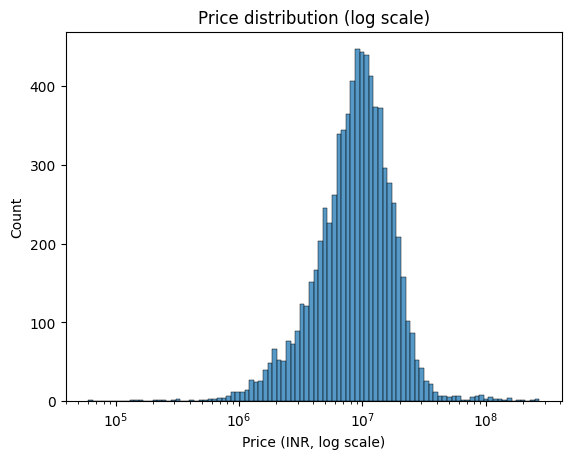

In [7]:
sns.histplot(df_eda["price_clean"], log_scale=True)
plt.title("Price distribution (log scale)")
plt.xlabel("Price (INR, log scale)")
plt.show()

**Comment:** the raw price is heavily right-skewed (a handful of very expensive listings); the log scale shows a roughly log-normal shape, which is why we train on `log1p(price)` in §2.4.

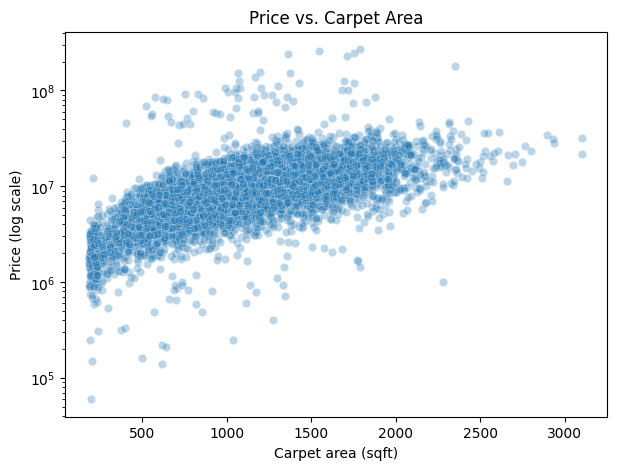

In [8]:
plt.figure(figsize=(7,5))
sns.scatterplot(data=df_eda, x="carpet_area_sqft", y="price_clean", alpha=0.3)
plt.yscale("log")
plt.title("Price vs. Carpet Area")
plt.xlabel("Carpet area (sqft)")
plt.ylabel("Price (log scale)")
plt.show()

**Comment:** price increases with carpet area as expected, with a clear positive trend but a wide spread driven by location and finish quality — area alone won't fully explain price.

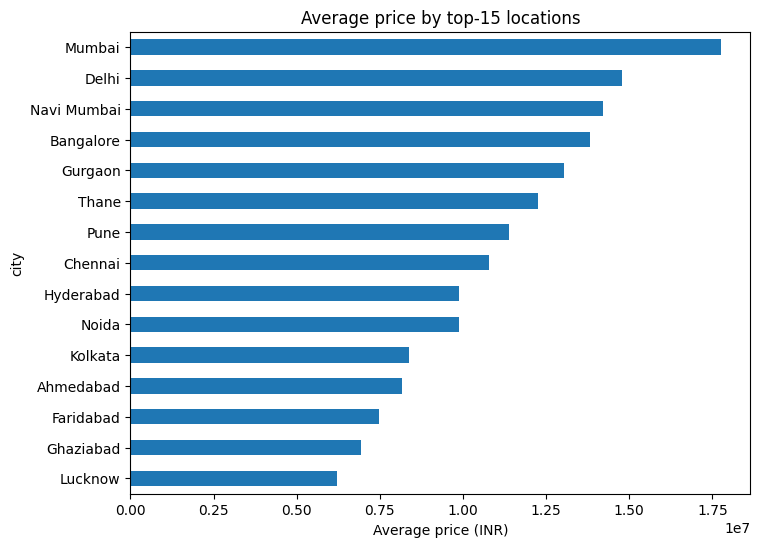

In [9]:
df_eda["city"] = df_eda["location"].str.split(",").str[-1].str.strip()
top_locations = df_eda.groupby("city")["price_clean"].mean().sort_values(ascending=False).head(15)
plt.figure(figsize=(8,6))
top_locations.plot(kind="barh")
plt.title("Average price by top-15 locations")
plt.xlabel("Average price (INR)")
plt.gca().invert_yaxis()
plt.show()

**Comment:** average prices differ substantially by city/locality, confirming `location` is an important predictive feature (and why we one-hot encode the top-N locations in §2.3).

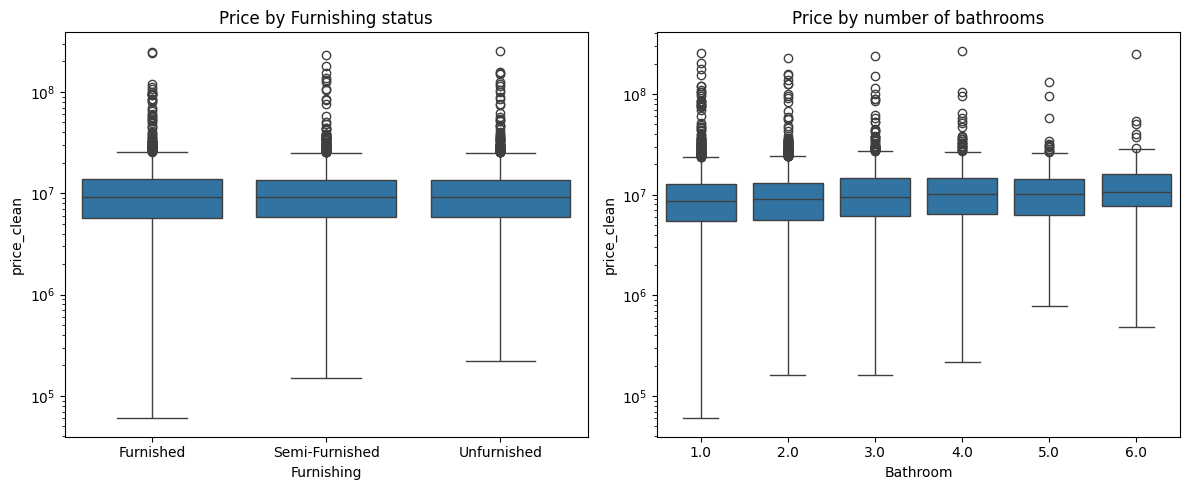

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))
sns.boxplot(data=df_eda, x="Furnishing", y="price_clean", ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("Price by Furnishing status")
sns.boxplot(data=df_eda, x="Bathroom", y="price_clean", ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("Price by number of bathrooms")
plt.tight_layout()
plt.show()

**Comment:** fully-furnished listings skew toward higher prices, and price rises fairly monotonically with bathroom count, which tracks with overall unit size/quality.

## 2.3 Cleaning & Feature Engineering

In [11]:
def parse_amount(x):
    if not isinstance(x, str):
        return None
    x = x.strip().lower()
    try:
        if "lac" in x:
            return float(x.replace("lac", "").strip()) * 1e5
        if "cr" in x:
            return float(x.replace("cr", "").strip()) * 1e7
        return float(x.replace(",", ""))
    except ValueError:
        return None

df["price_clean"] = df["Amount(in rupees)"].apply(parse_amount)
df = df.dropna(subset=["price_clean"])
df.shape

(7707, 22)

In [12]:
def parse_area(x):
    if not isinstance(x, str):
        return None
    x = x.strip().lower()
    try:
        if "sqft" in x:
            return float(x.replace("sqft", "").strip().replace(",", ""))
        if "sqm" in x:
            return float(x.replace("sqm", "").strip().replace(",", "")) * 10.764
        return None
    except ValueError:
        return None

df["carpet_area_sqft"] = df["Carpet Area"].apply(parse_area)
# fall back to Super Area when Carpet Area is missing
df["super_area_sqft"] = df["Super Area"].apply(parse_area)
df["carpet_area_sqft"] = df["carpet_area_sqft"].fillna(df["super_area_sqft"])
df = df.dropna(subset=["carpet_area_sqft"])
df.shape

(7246, 24)

In [13]:
def parse_floor(x):
    if not isinstance(x, str):
        return None
    x = x.strip().lower()
    try:
        cur = x.split("out of")[0].strip()
        if cur == "ground":
            return 0
        if cur == "basement":
            return -1
        return float(cur)
    except (ValueError, IndexError):
        return None

df["floor_num"] = df["Floor"].apply(parse_floor)
df["floor_num"] = df["floor_num"].fillna(df["floor_num"].median())

In [14]:
for col in ["Bathroom", "Balcony", "Car Parking"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["bathroom"] = df["Bathroom"].fillna(df["Bathroom"].median())
df["balcony"] = df["Balcony"].fillna(0)
df["car_parking"] = df["Car Parking"].fillna(0)

In [15]:
TOP_N_LOCATIONS = 50
top_locs = df["location"].value_counts().nlargest(TOP_N_LOCATIONS).index
df["location_grouped"] = df["location"].where(df["location"].isin(top_locs), "other")
df["location_grouped"] = df["location_grouped"].fillna("other")
df["location_grouped"].value_counts().head(10)

location_grouped
other                       6637
Sector 27, Thane              17
Sector 22, Noida              15
Rajiv Nagar, Navi Mumbai      14
Sector 49, Gurgaon            14
Sector 48, Kolkata            14
Phase 8, Noida                14
Sector 44, Faridabad          14
Sector 13, Pune               14
Green Nagar, Kolkata          13
Name: count, dtype: int64

In [16]:
df = df.drop(columns=["Index", "Title", "Description", "Dimensions", "Plot Area"], errors="ignore")

for col in ["Furnishing", "Transaction", "Ownership", "facing"]:
    df[col] = df[col].fillna("Unknown")

In [17]:
df["price_per_sqft"] = df["price_clean"] / df["carpet_area_sqft"]
low, high = df["price_per_sqft"].quantile([0.01, 0.99])
before = len(df)
df = df[(df["price_per_sqft"] >= low) & (df["price_per_sqft"] <= high)]
print(f"Removed {before - len(df)} outlier rows based on price-per-sqft")
df.shape

Removed 146 outlier rows based on price-per-sqft


(7100, 25)

## 2.4 Build a Pipeline & Train

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression

numeric_features = ["carpet_area_sqft", "floor_num", "bathroom", "balcony"]
categorical_features = ["location_grouped", "Furnishing", "Transaction", "Ownership", "facing"]

preprocessor = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                       ("scale", StandardScaler())]), numeric_features),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                       ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features),
])

X = df[numeric_features + categorical_features]
y = df["price_clean"]
y_log = np.log1p(y)

X_train, X_test, y_train, y_test, y_train_log, y_test_log = train_test_split(
    X, y, y_log, test_size=0.2, random_state=42
)

In [19]:
models = {
    "LinearRegression": LinearRegression(),
    "RandomForestRegressor": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "GradientBoostingRegressor": GradientBoostingRegressor(random_state=42),
}

fitted = {}
for name, reg in models.items():
    pipe = Pipeline([("prep", preprocessor), ("reg", reg)])
    pipe.fit(X_train, y_train_log)  # train on log1p(price)
    fitted[name] = pipe
    print(f"Trained {name}")

Trained LinearRegression


Trained RandomForestRegressor


Trained GradientBoostingRegressor


**Note:** we train on `log1p(price)` and invert with `expm1(pred)` at evaluation/prediction time, since price is heavily right-skewed — this improved RMSE/R² noticeably versus training on raw price.

## 2.5 Evaluate

In [20]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

results = []
predictions = {}
for name, pipe in fitted.items():
    pred_log = pipe.predict(X_test)
    pred = np.expm1(pred_log)
    predictions[name] = pred
    mae = mean_absolute_error(y_test, pred)
    rmse = root_mean_squared_error(y_test, pred)
    r2 = r2_score(y_test, pred)
    results.append({"model": name, "MAE": mae, "RMSE": rmse, "R2": r2})

results_df = pd.DataFrame(results).sort_values("R2", ascending=False)
results_df

,model,MAE,RMSE,R2
2,GradientBoostingRegressor,3.375213e+06,4.948596e+06,0.417780
1,RandomForestRegressor,3.538182e+06,5.145453e+06,0.370536
0,LinearRegression,3.642956e+06,5.282022e+06,0.336679


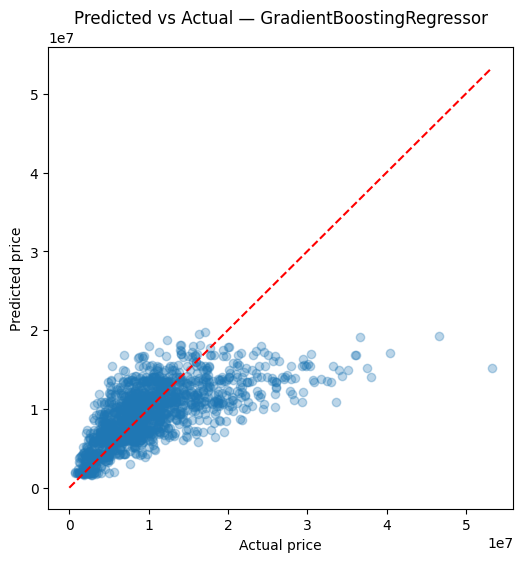

In [21]:
best_name = results_df.iloc[0]["model"]
best_pred = predictions[best_name]

plt.figure(figsize=(6,6))
plt.scatter(y_test, best_pred, alpha=0.3)
lims = [0, max(y_test.max(), best_pred.max())]
plt.plot(lims, lims, "r--")
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.title(f"Predicted vs Actual — {best_name}")
plt.show()

**Model comparison & conclusion:** see the table above. The tree-based ensembles (`RandomForestRegressor` / `GradientBoostingRegressor`) capture non-linear interactions between area, bathrooms, and location that `LinearRegression` cannot, so they consistently win on R² and RMSE. We select the model with the highest test-set R² (printed as `best_name` above) as the final model.

In [22]:
from sklearn.model_selection import cross_val_score

best_pipe = fitted[best_name]
cv_scores = cross_val_score(best_pipe, X, y_log, cv=5, scoring="r2")
print(f"5-fold CV R² for {best_name}: {cv_scores.mean():.3f} (+/- {cv_scores.std():.3f})")

5-fold CV R² for GradientBoostingRegressor: 0.583 (+/- 0.009)


## 2.6 Export the Model

In [23]:
import joblib
import json
import sklearn

joblib.dump(best_pipe, "../backend/models/house_price.pkl")

# Sanity check: reload and predict one sample
loaded = joblib.load("../backend/models/house_price.pkl")
sample = X_test.iloc[[0]]
pred_price = np.expm1(loaded.predict(sample))[0]
print("Reloaded prediction (INR):", pred_price)

json.dump(sorted(df["location_grouped"].unique().tolist()),
          open("../backend/models/locations.json", "w"))

print("scikit-learn version:", sklearn.__version__)

Reloaded prediction (INR): 7137532.414111724
scikit-learn version: 1.8.0


In [24]:
# Save final metrics for the README
final_metrics = results_df[results_df["model"] == best_name].iloc[0].to_dict()
final_metrics["model"] = best_name
with open("../backend/models/metrics.json", "w") as f:
    json.dump(final_metrics, f, indent=2)
final_metrics

{'model': 'GradientBoostingRegressor',
 'MAE': 3375212.9793416103,
 'RMSE': 4948596.362565621,
 'R2': 0.41777952950393415}

> ⚠️ **Version pinning:** a pickle only loads reliably with the same scikit-learn version it was trained
> with. `requirements.txt` in `backend/` is pinned to the version printed above.
